# dE/dx and dx Segment Analysis Notebook

This notebook is designed to analyze and visualize the $dE/dx$ distributions, comparison of fitted vs. true values, the impact of step length ($dx$), and the comparison between the mean, MPV, prior distributions, and the Split Student-t fit.

### Features:
1. **$dE/dx$ True Distribution**: Histogram of track segment $dE/dx$, showing the asymmetric landau-like shape, the true mean, the MPV, and the Student-t prior.
2. **Symmetric vs. Split Student-t Prior**: Comparison of symmetric priors with the bifurcated Split Student-t fit from `dedx_proto.ipynb` Cell 13.
3. **Fitted vs. True $dE/dx$**: Correlation plots and residuals.
4. **Impact of $dx$ (Step Length)**: Residuals as a function of segment length, bin-by-bin statistics, and outlier analysis.

In [1]:
import os
import glob
import pickle
import numpy as np
import matplotlib.pyplot as plt
import h5py
from scipy.stats import t as student_t

# Set aesthetic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'figure.titlesize': 18
})

In [2]:
# ==========================================
# 1. Load Data & Extract True dE/dx
# ==========================================

target_file_path = "/sdf/data/neutrino/cyifan/diffsim_input/true_through_muon_edep_10cm_vol1cm.h5"

# Search for the latest fit history pkl
fit_results_pattern = "/sdf/group/neutrino/pgranger/larnd-sim-jax/fit_result/fit_noise_fit_dedx_*/history_iter*.pkl"
pkl_files = glob.glob(fit_results_pattern)

if pkl_files:
    pkl_files.sort(key=os.path.getmtime)
    pkl_path = pkl_files[-1]
    print(f"Loading latest fit history: {pkl_path}")
    with open(pkl_path, 'rb') as f:
        fit_data = pickle.load(f)
else:
    print("No fit history pickle files found. Analyzing target file only.")
    fit_data = None

# Extract true dEdx and dx from target HDF5
with h5py.File(target_file_path, 'r') as f:
    segments = f['segments'][:]
    
dx = segments['dx']
dE = segments['dE']
valid_mask = (dx > 0) & (dE > 0)
true_dedx = dE[valid_mask] / dx[valid_mask]
true_dx = dx[valid_mask]

# Calculate statistics
mean_dedx = np.mean(true_dedx)
median_dedx = np.median(true_dedx)
counts, bin_edges = np.histogram(true_dedx, bins=1000, range=(1.0, 3.5))
mpv_dedx = bin_edges[np.argmax(counts) + 1]

print("\n--- True dE/dx statistics from target file ---")
print(f"Mean dE/dx:    {mean_dedx:.4f} MeV/cm")
print(f"Median dE/dx:  {median_dedx:.4f} MeV/cm")
print(f"MPV (mode):    {mpv_dedx:.4f} MeV/cm")

Loading latest fit history: /sdf/group/neutrino/pgranger/larnd-sim-jax/fit_result/fit_noise_fit_dedx_27237082/history_iter5000_true_throughmuons_1dfit_fit_dedx_priw0.5_dlr1e-2_dsi0_noise_tgtsim_n_neigh4_mode_lut_e_sampling_0.01cm_seed_stgy_random_grad_clip100_warmup_exponential_decay_schedule_bt200_tgtsd7_dtsd1_adam_llhd.pkl

--- True dE/dx statistics from target file ---
Mean dE/dx:    1.8854 MeV/cm
Median dE/dx:  1.8689 MeV/cm
MPV (mode):    1.8750 MeV/cm


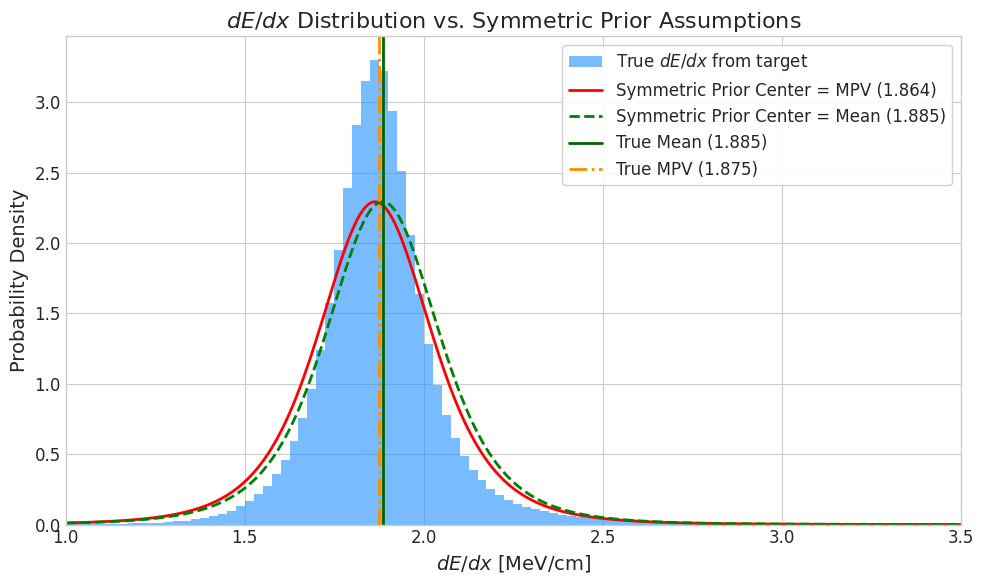

Key Takeaway:
The true dE/dx distribution is highly asymmetric (long Landau tail).
Centering the symmetric prior at the MPV (1.864) creates a mismatch: the prior pulls dE/dx
lower than its true mean (1.885), causing the calibration parameters to bias to compensate.
Centering the prior at the true mean (1.885) removes this systematic offset.


In [3]:
# ==========================================
# 2. Symmetric Student-t Priors vs True dE/dx
# ==========================================

plt.figure(figsize=(10, 6))
plt.hist(true_dedx, bins=100, range=(1.0, 3.5), density=True, alpha=0.6, color='dodgerblue', label='True $dE/dx$ from target')

# Define prior parameters
nu = 4.22
scale = 0.164
loc_mpv = 1.864 # prior center set to MPV
loc_mean = 1.885 # prior center set to true mean

x_eval = np.linspace(1.0, 3.5, 500)
pdf_mpv = student_t.pdf(x_eval, df=nu, loc=loc_mpv, scale=scale)
pdf_mean = student_t.pdf(x_eval, df=nu, loc=loc_mean, scale=scale)

# Plot prior curves
plt.plot(x_eval, pdf_mpv, 'r-', lw=2, label='Symmetric Prior Center = MPV (1.864)')
plt.plot(x_eval, pdf_mean, 'g--', lw=2, label='Symmetric Prior Center = Mean (1.885)')

# Highlight statistics
plt.axvline(mean_dedx, color='darkgreen', linestyle='-', lw=2, label=f'True Mean ({mean_dedx:.3f})')
plt.axvline(mpv_dedx, color='darkorange', linestyle='-.', lw=2, label=f'True MPV ({mpv_dedx:.3f})')

plt.title('$dE/dx$ Distribution vs. Symmetric Prior Assumptions')
plt.xlabel('$dE/dx$ [MeV/cm]')
plt.ylabel('Probability Density')
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.xlim(1.0, 3.5)
plt.tight_layout()
plt.show()

print("Key Takeaway:")
print("The true dE/dx distribution is highly asymmetric (long Landau tail).")
print("Centering the symmetric prior at the MPV (1.864) creates a mismatch: the prior pulls dE/dx")
print("lower than its true mean (1.885), causing the calibration parameters to bias to compensate.")
print("Centering the prior at the true mean (1.885) removes this systematic offset.")

--- Fitted Split Student-t Parameters ---
Location (mode):   1.8752
Left side:         nu_L = 4.835, scale_L = 0.1210
Right side:        nu_R = 2.010, scale_R = 0.1047


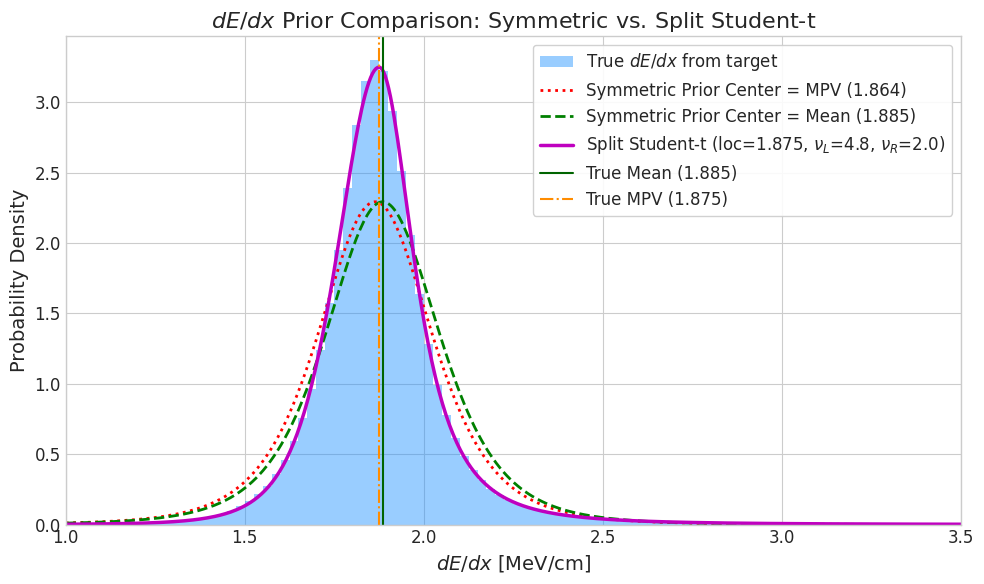

In [ ]:
# ==========================================
# 3. Split (Bifurcated) Student-t Prior Fit (dedx_proto.ipynb Cell 13)
# ==========================================

import jax
import jax.numpy as jnp
import jax.scipy.stats as jstats
import optax

# JAX-native Split Student-t log-pdf
def split_t_logpdf_jax(x, nu_L, nu_R, loc, scale_L, scale_R):
    def log_c(nu):
        return (jax.scipy.special.gammaln((nu + 1.0) / 2.0)
                - jax.scipy.special.gammaln(nu / 2.0)
                - 0.5 * jnp.log(nu * jnp.pi))

    log_c_L = log_c(nu_L)
    log_c_R = log_c(nu_R)

    z_L = (x - loc) / scale_L
    z_R = (x - loc) / scale_R

    log_K_L = jstats.t.logpdf(z_L, df=nu_L, loc=0.0, scale=1.0) - log_c_L
    log_K_R = jstats.t.logpdf(z_R, df=nu_R, loc=0.0, scale=1.0) - log_c_R

    Z_L = 0.5 * scale_L * jnp.exp(-log_c_L)
    Z_R = 0.5 * scale_R * jnp.exp(-log_c_R)
    log_Z = jnp.log(Z_L + Z_R)

    log_K = jnp.where(x < loc, log_K_L, log_K_R)
    return log_K - log_Z

# Fit target function (Negative Log-Likelihood)
def split_loss_fn(p, x):
    nu_L    = jax.nn.softplus(p['nu_L_raw'])    + 1.0
    nu_R    = jax.nn.softplus(p['nu_R_raw'])    + 1.0
    scale_L = jax.nn.softplus(p['scale_L_raw'])
    scale_R = jax.nn.softplus(p['scale_R_raw'])
    loc     = p['loc']
    return -jnp.mean(split_t_logpdf_jax(x, nu_L=nu_L, nu_R=nu_R, loc=loc,
                                         scale_L=scale_L, scale_R=scale_R))

# Prepare data (MIP region: 1.0 to 5.0 MeV/cm)
split_data = true_dedx#[(true_dedx > 1.0) & (true_dedx < 9.0)]
split_data_jnp = jnp.array(split_data)

# Initialize parameters
std_val = float(np.std(split_data))
p0 = {
    'nu_L_raw':    jnp.array(5.0),
    'nu_R_raw':    jnp.array(1.0),
    'loc':         jnp.median(split_data_jnp),
    'scale_L_raw': jnp.array(std_val * 0.5),
    'scale_R_raw': jnp.array(std_val * 1.5),
}

# Optax Optimizer
opt = optax.adam(0.05)
opt_state = opt.init(p0)

@jax.jit
def step(p, s, x):
    loss, g = jax.value_and_grad(split_loss_fn)(p, x)
    upd, ns = opt.update(g, s, p)
    return optax.apply_updates(p, upd), ns, loss

# Optimize
params = p0
for ep in range(1000):
    params, opt_state, loss_val = step(params, opt_state, split_data_jnp)

# Extract fitted values
fit_nu_L = float(jax.nn.softplus(params['nu_L_raw']) + 1.0)
fit_nu_R = float(jax.nn.softplus(params['nu_R_raw']) + 1.0)
fit_scale_L = float(jax.nn.softplus(params['scale_L_raw']))
fit_scale_R = float(jax.nn.softplus(params['scale_R_raw']))
fit_loc = float(params['loc'])

print("--- Fitted Split Student-t Parameters ---")
print(f"Location (mode):   {fit_loc:.4f}")
print(f"Left side:         nu_L = {fit_nu_L:.3f}, scale_L = {fit_scale_L:.4f}")
print(f"Right side:        nu_R = {fit_nu_R:.3f}, scale_R = {fit_scale_R:.4f}")

lb = 1.0
hb = 3.5

# Plot Comparison
plt.figure(figsize=(10, 6))
plt.hist(true_dedx, bins=100, range=(lb, hb), density=True, alpha=0.45, color='dodgerblue', label='True $dE/dx$ from target')

# Evaluate fitted Split Student-t PDF
x_eval = np.linspace(lb, hb, 500)
pdf_split = np.exp(np.array(split_t_logpdf_jax(
    jnp.array(x_eval), nu_L=fit_nu_L, nu_R=fit_nu_R,
    loc=fit_loc, scale_L=fit_scale_L, scale_R=fit_scale_R)))

# Plot prior curves
plt.plot(x_eval, pdf_mpv, 'r:', lw=2, label='Symmetric Prior Center = MPV (1.864)')
plt.plot(x_eval, pdf_mean, 'g--', lw=2, label='Symmetric Prior Center = Mean (1.885)')
plt.plot(x_eval, pdf_split, 'm-', lw=2.5, label=f'Split Student-t (loc={fit_loc:.3f}, $\\nu_L$={fit_nu_L:.1f}, $\\nu_R$={fit_nu_R:.1f})')

# Highlight statistics
plt.axvline(mean_dedx, color='darkgreen', linestyle='-', lw=1.5, label=f'True Mean ({mean_dedx:.3f})')
plt.axvline(mpv_dedx, color='darkorange', linestyle='-.', lw=1.5, label=f'True MPV ({mpv_dedx:.3f})')

plt.title('$dE/dx$ Prior Comparison: Symmetric vs. Split Student-t')
plt.xlabel('$dE/dx$ [MeV/cm]')
plt.ylabel('Probability Density')
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.xlim(lb, hb)
plt.tight_layout()
plt.show()

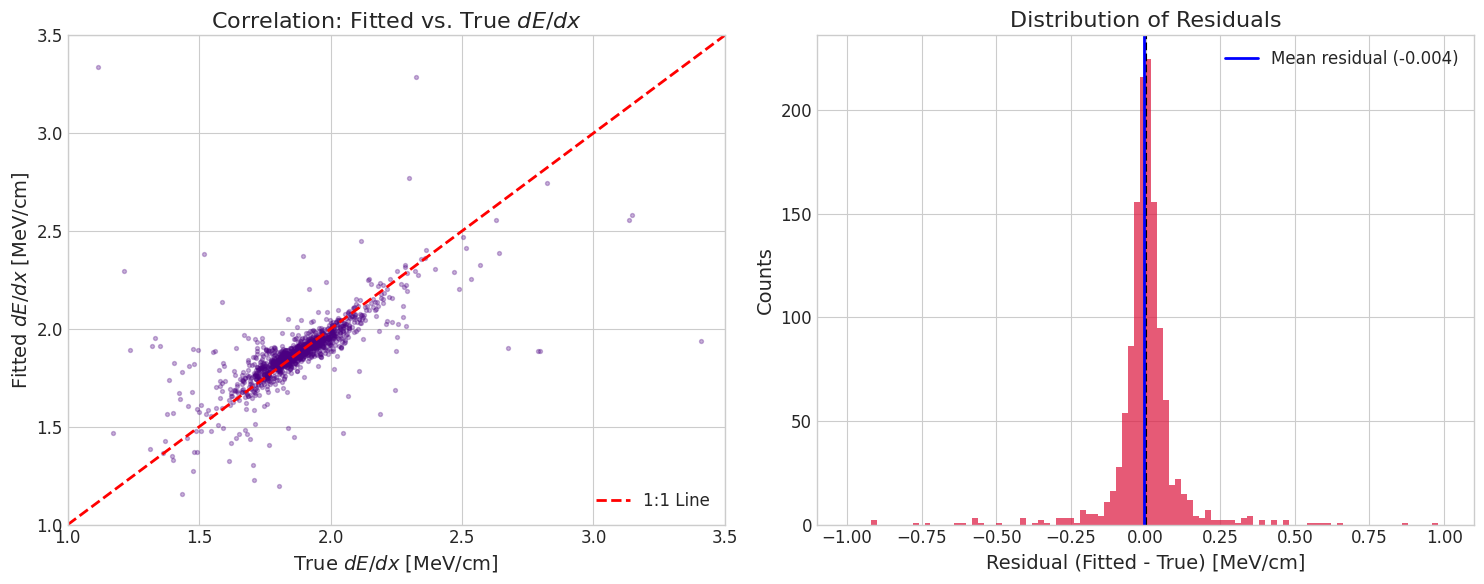

Overall Mean Absolute Error (MAE): 0.0722 MeV/cm
Overall Mean Residual (Bias):     -0.0043 MeV/cm


In [5]:
# ==========================================
# 4. Compare Fitted vs. True dE/dx (From Caches)
# ==========================================

if fit_data is not None and 'dedx_cache' in fit_data and 'true_dedx_cache' in fit_data:
    cache = fit_data['dedx_cache']
    true_cache = fit_data['true_dedx_cache']
    
    fitted_vals = []
    true_vals = []
    
    for batch_idx in sorted(cache.keys()):
        entry = cache[batch_idx]
        log_dedx = entry.get('log_dedx')
        if log_dedx is None: continue
        
        f_val = np.exp(np.asarray(log_dedx, dtype=float).ravel())
        t_val = true_cache.get(batch_idx, true_cache.get(int(batch_idx)))
        if t_val is None: continue
        t_val = np.asarray(t_val, dtype=float).ravel()
        
        n = min(len(f_val), len(t_val))
        fitted_vals.extend(f_val[:n])
        true_vals.extend(t_val[:n])
        
    fitted_vals = np.array(fitted_vals)
    true_vals = np.array(true_vals)
    residuals = fitted_vals - true_vals
    
    # Plot Fitted vs True
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    # 2D scatter / profile plot
    axes[0].scatter(true_vals, fitted_vals, alpha=0.3, color='indigo', s=8)
    axes[0].plot([1.0, 3.5], [1.0, 3.5], 'r--', lw=2, label='1:1 Line')
    axes[0].set_xlabel('True $dE/dx$ [MeV/cm]')
    axes[0].set_ylabel('Fitted $dE/dx$ [MeV/cm]')
    axes[0].set_title('Correlation: Fitted vs. True $dE/dx$')
    axes[0].set_xlim(1.0, 3.5)
    axes[0].set_ylim(1.0, 3.5)
    axes[0].legend()
    
    # Residuals histogram
    axes[1].hist(residuals, bins=100, range=(-1.0, 1.0), color='crimson', alpha=0.7)
    axes[1].axvline(0, color='black', linestyle='--', lw=1.5)
    axes[1].axvline(np.mean(residuals), color='blue', linestyle='-', lw=2, label=f'Mean residual ({np.mean(residuals):+.3f})')
    axes[1].set_xlabel('Residual (Fitted - True) [MeV/cm]')
    axes[1].set_ylabel('Counts')
    axes[1].set_title('Distribution of Residuals')
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()
    
    print(f"Overall Mean Absolute Error (MAE): {np.mean(np.abs(residuals)):.4f} MeV/cm")
    print(f"Overall Mean Residual (Bias):     {np.mean(residuals):.4f} MeV/cm")
else:
    print("Fitted dE/dx caches not available in the loaded history file.")

In [ ]:
# ==========================================
# 5. Segment Length (dx) Analysis & Impact on Errors
# ==========================================

# Plot step length (dx) distribution
plt.figure(figsize=(10, 5))
plt.hist(true_dx, bins=100, range=(0.0, 1.0), color='teal', alpha=0.7)
plt.title('Distribution of Track Segment Lengths ($dx$)')
plt.xlabel('Segment Length $dx$ [cm]')
plt.ylabel('Counts')
plt.yscale('log')
plt.tight_layout()
plt.show()

print(f"Mean segment length:   {np.mean(true_dx):.4f} cm")
print(f"Median segment length: {np.median(true_dx):.4f} cm")

# If fit history is loaded, match fitted segments to their actual dx lengths
if fit_data is not None and 'dedx_cache' in fit_data and 'true_dedx_cache' in fit_data:
    import sys
    sys.path.append("/sdf/group/neutrino/pgranger/larnd-sim-jax")
    from optimize.dataio import TracksDataset
    
    config = fit_data.get('config')
    c_dict = vars(config) if hasattr(config, '__dict__') else config
    
    print("\nRecreating dataset to match segment lengths...")
    dataset = TracksDataset(
        filename=c_dict.get('input_file_sim'),
        nevents=c_dict.get('data_sz', -1),
        max_nbatch=c_dict.get('max_nbatch'),
        random_nevents=c_dict.get('random_nevents', False),
        data_seed=c_dict.get('data_seed', 42),
        track_len_sel=c_dict.get('track_len_sel', 2.0),
        max_abs_costheta_sel=c_dict.get('max_abs_costheta_sel', 0.966),
        min_abs_segz_sel=c_dict.get('min_abs_segz_sel', 15.0),
        track_z_bound=c_dict.get('track_z_bound', 28.0),
        max_batch_len=c_dict.get('max_batch_len', 50),
        print_input=False,
        chopped=not c_dict.get('no_chop', False),
        pad=not c_dict.get('no_pad', False),
        electron_sampling_resolution=c_dict.get('electron_sampling_resolution', 0.1),
        live_selection=c_dict.get('live_selection', False)
    )
    
    # Load all batches
    for b in range(len(dataset)):
        _ = dataset[b]
        
    matched_dx = []
    matched_residuals = []
    
    for batch_idx in sorted(cache.keys()):
        entry = cache[batch_idx]
        log_dedx = entry.get('log_dedx')
        if log_dedx is None: continue
        
        f_val = np.exp(np.asarray(log_dedx, dtype=float).ravel())
        t_val = true_cache.get(batch_idx, true_cache.get(int(batch_idx)))
        if t_val is None: continue
        t_val = np.asarray(t_val, dtype=float).ravel()
        
        traj_indices = dataset.batch_traj_indices[batch_idx]
        rows_list = [dataset.trajectory_row_indices[t] for t in traj_indices]
        rows = np.concatenate(rows_list)
        selected_struct = dataset.tracks_struct[rows]
        
        n = min(len(f_val), len(t_val), len(selected_struct))
        for j in range(n):
            matched_dx.append(float(selected_struct[j]['dx']))
            matched_residuals.append(float(f_val[j] - t_val[j]))
            
    matched_dx = np.array(matched_dx)
    matched_residuals = np.array(matched_residuals)
    matched_abs_res = np.abs(matched_residuals)
    
    # Plot residuals vs dx
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    axes[0].scatter(matched_dx, matched_residuals, alpha=0.3, color='teal', s=10)
    axes[0].axhline(0, color='black', linestyle='--', lw=1.5)
    axes[0].set_xlabel('Segment Length $dx$ [cm]')
    axes[0].set_ylabel('Residual (Fitted - True) [MeV/cm]')
    axes[0].set_title('Residual vs. Segment Length')
    axes[0].set_xlim(0.0, 1.0)
    
    # Bin by dx and plot Mean Absolute Error (MAE)
    bins = np.linspace(0.0, 1.0, 11)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    bin_mae = []
    bin_std = []
    
    for i in range(len(bins)-1):
        mask = (matched_dx >= bins[i]) & (matched_dx < bins[i+1])
        if np.sum(mask) > 0:
            bin_mae.append(np.mean(matched_abs_res[mask]))
            bin_std.append(np.std(matched_residuals[mask]))
        else:
            bin_mae.append(np.nan)
            bin_std.append(np.nan)
            
    axes[1].errorbar(bin_centers, bin_mae, yerr=bin_std, fmt='o-', color='purple', capsize=4, label='MAE $\pm$ std(Residual)')
    axes[1].set_xlabel('Segment Length $dx$ [cm]')
    axes[1].set_ylabel('Mean Absolute Error [MeV/cm]')
    axes[1].set_title('MAE vs. Segment Length ($dx$)')
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics for different length bins
    print("\n--- Error statistics by segment length (dx) ---")
    length_thresholds = [0.05, 0.1, 0.2, 0.5]
    for i, thresh in enumerate(length_thresholds):
        if i == 0:
            mask = (matched_dx < thresh)
            label = f"dx < {thresh} cm"
        else:
            prev = length_thresholds[i-1]
            mask = (matched_dx >= prev) & (matched_dx < thresh)
            label = f"{prev} <= dx < {thresh} cm"
        print(f"{label:<25} | count = {np.sum(mask):<5} | MAE = {np.mean(matched_abs_res[mask]):.4f} MeV/cm | std = {np.std(matched_residuals[mask]):.4f}")
    
    mask = (matched_dx >= length_thresholds[-1])
    print(f"dx >= {length_thresholds[-1]} cm{'':<14} | count = {np.sum(mask):<5} | MAE = {np.mean(matched_abs_res[mask]):.4f} MeV/cm | std = {np.std(matched_residuals[mask]):.4f}")

else:
    print("Caching of matched dx is unavailable. Run a full fit with dEdx tracking enabled to produce history files.")